## Current workflow review copy

Synchronized with the completed 09 October 2026 uncalibrated engine run. Cluster assignments and household sampling are retained; thermal simulations now use cluster-median construction profiles at three median floor areas. Notebooks 05 onward use outputs/current. Notebooks 03–04 have no saved demonstration outputs in the current source. Read [the workflow](../../docs/ENGINE_WORKFLOW.md) and [interpretation](../../docs/INTERPRETATION.md). Packaging does not rerun calculations. Raw data, address-level outputs and interactive payloads are excluded.


In [ ]:
# Review copy: read saved results without running the research pipeline.
import os
if os.environ.get("ENERMAP_ENABLE_MODEL_RUN") != "1":
    raise RuntimeError("Review copy: source inputs and third-party engines are excluded. Read saved results or use the Streamlit app.")
import sys
from pathlib import Path
_repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.py").exists())
sys.path.insert(0, str(_repo))


# U4: electrification, rooftop PV and existing substation capacity

**Research question:** How does adding up to 4 kWp of rooftop PV per dwelling change hourly grid imports, exports and residential loading against existing substation ratings?

This notebook adapts the hourly building and substation balance in Park and Wang (2024), *Buildings* 14, 3398 ([paper](https://doi.org/10.3390/buildings14113398), Figures 9–11). It uses EnerMap's completed residential demand model, assessed rooftop PV and existing nearest-substation assignments. Thermal simulations are not rerun.

The main cases are **U0 existing heating / no PV**, **U1 electrification / no PV**, and **U4 electrification / PV capped at 4 kWp per dwelling**. Transformer ratings remain fixed. U0 is gross modelled residential load, not measured substation loading; an installed-PV inventory is unavailable.

For houses, the cap applies to the house. For flats, it applies to the existing allocated dwelling share of the shared roof, as in current U4. Summed allocations are checked against source roofs. This does not assume an independent array or verified meter connection for every flat.

## 1. Relation to the paper and the 4 kWp cap

Section 4 of the Sheffield paper assumes **12% PV efficiency, an 80% performance ratio and 60% roof utilisation**. It states no additional per-property kWp cap. Its result is assessed suitable-roof potential under those assumptions, rather than every square metre of roof.

Here, **4 kWp is the main scenario cap**. Energy Saving Trust currently describes an average domestic system of around **4.5 kWp** ([source, accessed 8 October 2026](https://energysavingtrust.org.uk/advice/solar-panels/?loc=england)), so 4 kWp is a reasonable, slightly smaller study assumption. kWp is panel nameplate capacity, not a permitted AC export limit. Existing suitable-roof yields are retained; the paper's efficiency and roof-use factors are not applied again.

An uncapped assessed-potential sensitivity is available but **off by default**. There is no battery or network reconfiguration.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'ukubem').is_dir():
    ROOT = next(p for p in ROOT.parents if (p / 'ukubem').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from analysis import u4_pv_balance as B

settings = B.Settings(
    output_dir='outputs/current/u4_pv_balance',
    power_factor=0.95,
    tilt_deg=35.0,
    orientation_sensitivity=True,
    full_potential_sensitivity=False,
)
study = B.load_study(settings)
assert study['cap_kWp'] == 4.0, 'Retain the requested 4 kWp cap in the current U4 parameter.'
print('Outputs:', study['out'])
display(study['coverage'])

LOCAL_PATH/core.py:35: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Outputs: LOCAL_PATH/u4_pv_balance


,item,count
0,Planning-area dwellings,28663
1,Included mapped dwellings,28662
2,Unassigned dwellings excluded,1
3,Included substation cells,271
4,Dwellings with positive PV potential,22219
5,Reported ratings available,271
6,Multi-transformer stations (rating basis unver...,6


## 2. Common scope and baseline ratings

All comparisons use planning-area dwellings with the retained substation assignment. Missing assignments are exported and excluded from every scenario consistently. The nearest substation is an inferred connection.

The rating screen uses reported **ONAN kVA as supplied**, converted to an illustrative kW threshold at power factor 0.95. Multi-transformer records are flagged: ratings are not multiplied because their per-unit/aggregate basis has not been independently verified. Non-residential demand and other customers are absent. Results are **residential capacity screens**, not observed headroom or confirmed overloads. No additional diversity factor is applied to simultaneous hourly demand.

In [2]:
rating_columns = ['modelled_dwellings', 'reported_rating_kVA', 'screen_rating_kW',
                  'numberoftransformers', 'customer_count', 'multiple_transformers']
display(study['cells'][rating_columns].describe(include='all').round(2))
display(study['cells'].loc[study['cells'].multiple_transformers, rating_columns])
print('Allocated rooftop potential:', round(study['x'].pv_kWp.sum()/1000,3), 'MWp')
print('After the 4 kWp cap:', round(study['x'].capped_kWp.sum()/1000,3), 'MWp')
display(pd.read_csv(study['out']/'largest_pv_allocations.csv').head(8))

,modelled_dwellings,reported_rating_kVA,screen_rating_kW,numberoftransformers,customer_count,multiple_transformers
count,271.00,271.00,271.00,271.00,271.00,271
unique,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,False
freq,NaN,NaN,NaN,NaN,NaN,265
mean,105.76,528.62,502.19,1.02,121.14,NaN
std,70.25,281.95,267.85,0.15,85.77,NaN
min,1.00,50.00,47.50,1.00,6.00,NaN
25%,51.00,315.00,299.25,1.00,59.50,NaN
50%,104.00,500.00,475.00,1.00,108.00,NaN
75%,148.50,500.00,475.00,1.00,171.50,NaN


,modelled_dwellings,reported_rating_kVA,screen_rating_kW,numberoftransformers,customer_count,multiple_transformers
zone_id,,,,,,
SUB:SPN-S000000171606,163,1300,1235.0,2,181,True
SUB:SPN-S000000171629,10,2000,1900.0,2,117,True
SUB:SPN-S000000171804,211,2000,1900.0,2,336,True
SUB:SPN-S000000174043,227,800,760.0,2,294,True
SUB:SPN-S000000174948,60,1800,1710.0,2,104,True
SUB:SPN-S000000181539,272,2000,1900.0,2,69,True


Allocated rooftop potential: 117.759 MWp
After the 4 kWp cap: 69.363 MWp


[Review copy: identifier-bearing output omitted.]


## 3. Hourly PV generation

For assessed capacity \(K_i\) and annual yield \(Y_i\) allocated to dwelling \(i\):

\[
K_i^{U4}=\min(K_i,4\;\mathrm{kWp}),\qquad
Y_i^{U4}=Y_i\frac{K_i^{U4}}{K_i},\qquad
G_{i,t}=Y_i^{U4}f_t,\quad\sum_{t=1}^{8760}f_t=1.
\]

Zero-potential roofs remain zero. \(G_{i,t}\) is mean kW over a one-hour interval; its hourly sum is kWh.

Hourly weights use Farnborough EPW irradiance transposed to a 35° south-facing plane with pvlib's isotropic model. Demand and PV share the fixed 8760-hour clock, with no daylight-saving shift; solar position uses interval midpoints. PV is zero when the sun is below the horizon.

This distributes **existing annual yield** over time, rather than recalculating annual potential. Individual roof directions and hourly shading are unresolved. An equal east/west shape tests timing sensitivity at unchanged annual yield. No inverter clipping or network export constraint is imposed; occasional output above DC nameplate is possible in this annual-normalised screen and is not an inverter design result.

In [3]:
solar = B.solar_shapes(study)
display(solar.groupby(solar.index.month).sum().rename_axis('month').round(4))
specific_yield = study['x'].pv_annual_kWh / study['x'].pv_kWp.replace(0,float('nan'))
shape_audit = pd.DataFrame({name: specific_yield*shape.max()
                           for name,shape in study['pv_shapes'].items()})
shape_audit.to_csv(study['out']/'implied_peak_PV_per_kWp.csv')
display(shape_audit.describe().round(4))

,south,east_west
month,,
1,0.0339,0.0226
2,0.0503,0.0394
3,0.0842,0.0759
4,0.1174,0.1203
5,0.1229,0.1400
6,0.1255,0.1474
7,0.1318,0.1501
8,0.1090,0.1188
9,0.0913,0.0870


,south,east_west
count,22219.0000,22219.0000
mean,0.8762,0.8147
std,0.0677,0.0630
min,0.6502,0.6045
25%,0.8261,0.7681
50%,0.8716,0.8104
75%,0.9213,0.8566
max,1.1151,1.0368


## 4. Electrical demand and energy balance

U1 and U4 have identical gross electricity demand. Heat-pump heat is divided by hourly COP, and hot water, electric showers and non-heating electricity retain current accounting. PV is never subtracted directly from useful heat or gas.

At each dwelling PV allocation:

\[
S_{i,t}=\min(D_{i,t},G_{i,t}),\quad
I_{i,t}=\max(D_{i,t}-G_{i,t},0),\quad
X_{i,t}=\max(G_{i,t}-D_{i,t},0).
\]

At inferred cell \(c\):

\[
N_{c,t}=\sum_{i\in c}(D_{i,t}-G_{i,t}),\quad
I_{c,t}=\max(N_{c,t},0),\quad X_{c,t}=\max(-N_{c,t},0).
\]

Cell PV absorption is \(\min(\sum_iD_{i,t},\sum_iG_{i,t})\). It includes one dwelling's surplus coinciding with a neighbour's demand. Dwelling self-consumption and cell absorption remain separate: an accounting boundary change does not create electricity, change wiring or guarantee tariff savings.

Area import is \(\sum_c I_{c,t}\), **not** \(\max(\sum_cN_{c,t},0)\). Imports and exports in different cells remain simultaneous and separate.

In [4]:
summary = B.run_balances(study)
columns = ['capacity_MWp','gross_demand_GWh','PV_GWh','meter_import_GWh',
           'meter_export_GWh','cell_import_GWh','cell_export_GWh',
           'dwelling_self_consumption_pct','cell_PV_absorption_pct',
           'coincident_cell_import_peak_MW']
display(summary[columns].round(3))

,capacity_MWp,gross_demand_GWh,PV_GWh,meter_import_GWh,meter_export_GWh,cell_import_GWh,cell_export_GWh,dwelling_self_consumption_pct,cell_PV_absorption_pct,coincident_cell_import_peak_MW
case,,,,,,,,,,
U0_existing_no_pv,0.000,121.277,0.000,121.277,0.000,121.277,0.000,NaN,NaN,42.132
U1_electrification_no_pv,0.000,202.778,0.000,202.778,0.000,202.778,0.000,NaN,NaN,110.419
U4_capped_south,69.363,202.778,75.247,168.386,40.855,161.367,33.835,45.705,55.034,110.419
U4_capped_east_west,69.363,202.778,75.247,167.378,39.847,160.400,32.868,47.045,56.319,110.419


## 5. Current annual approximation versus hourly matching

Original U4 assigns 45% of annual PV to self-consumption and 55% to export. Here, the split is calculated from coincident demand. The fixed share is a comparator only and is not deducted again. The cell-boundary row represents a different metering boundary, not automatic collective billing.

In [5]:
display(study['fixed_split_comparison'].round(3))

,method,self_or_local_absorption_pct,import_GWh,export_GWh
0,Original fixed annual split,45.000,168.918,41.386
1,Hourly dwelling matching,45.705,168.386,40.855
2,Hourly cell boundary matching,55.034,161.367,33.835


## 6. Substation-cell geography

Illustrative Voronoi cells are regenerated from all supplied secondary-substation points and clipped to the original ten-ward boundary. Hourly demand retains the original ID assignment. Geometric exceptions are exported rather than silently changing membership. Light-grey cells have no matched modelled residential load; they are not assumed to have zero real network demand.

In [6]:
polygons = B.make_cells(study)
display(pd.DataFrame([study['checks']['mapped_points_in_illustrative_cells']]))
figures = B.make_figures(study)
print('Saved',len(figures),'figures, each as PNG and PDF.')

LOCAL_PATH/raw.py:723: RuntimeWarning: Cannot find tms_NZTM2000.json (GDAL_DATA is not defined)
  ogr_write(


,passed,inside,total,note
0,True,28662,28662,Map geometry only; hourly membership always us...


Saved 8 figures, each as PNG and PDF.


### Annual solar PV potential per secondary-substation cell

Annual generation potential is aggregated from the existing residential rooftop allocations:

\[
Y_c^{\mathrm{assessed}}=\sum_{i\in c}Y_i,\qquad
Y_c^{\mathrm{capped}}=\sum_{i\in c}Y_i\frac{\min(K_i,4\,\mathrm{kWp})}{K_i}.
\]

Zero-potential allocations contribute zero. Values are **MWh/year per cell**, before self-consumption or export. Both maps use the same colour scale. Full assessed potential retains the roof assessment's suitability and yield assumptions; it removes only the additional 4 kWp dwelling cap.

Scope is the included residential stock inside the planning boundary, assigned using the original secondary-substation IDs. Shared-roof shares are summed without duplicating whole roofs. Grey cells have no included residential records, not necessarily zero solar potential. This is an annual inventory; it does not enable the optional full-potential hourly scenario or change U4.

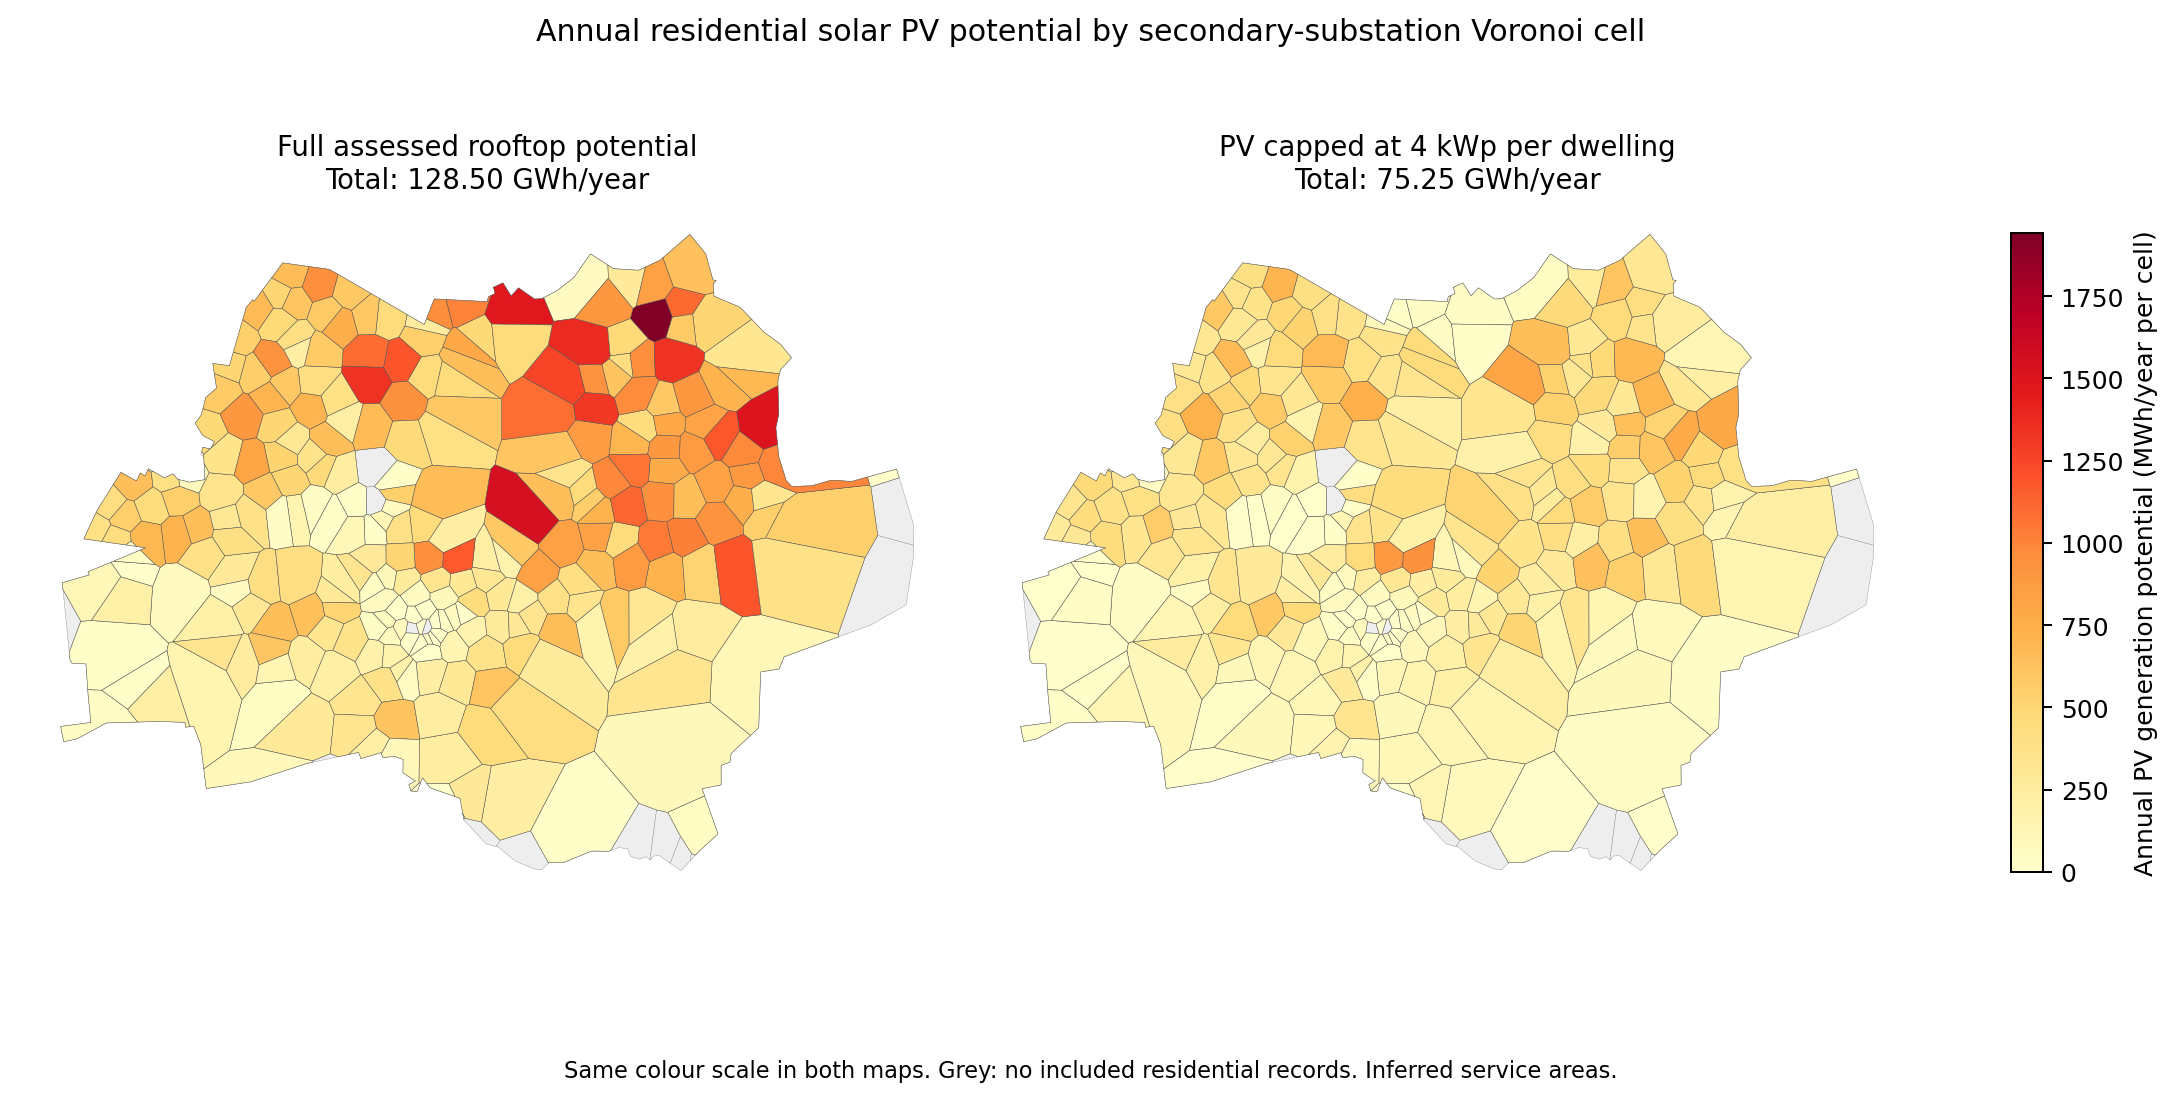

,modelled_dwellings,dwellings_with_PV_potential,assessed_capacity_kWp,assessed_annual_PV_kWh,capped_capacity_kWp,capped_annual_PV_kWh,assessed_annual_PV_MWh,capped_annual_PV_MWh,potential_removed_by_cap_MWh,potential_retained_pct
zone_id,,,,,,,,,,
SUB:SPN-S000000171856,127,112,1685.52,1941831.99,397.38,460344.74,1941.83,460.34,1481.49,23.71
SUB:SPN-S000000171710,121,114,1342.98,1547033.14,440.74,509897.57,1547.03,509.90,1037.14,32.96
SUB:SPN-S000000174640,199,190,1319.61,1502512.77,683.45,782885.99,1502.51,782.89,719.63,52.11
SUB:SPN-S000000174914,9,8,1231.05,1475716.89,32.00,38512.73,1475.72,38.51,1437.20,2.61
SUB:SPN-S000000171839,153,144,1196.64,1375210.16,569.40,653059.40,1375.21,653.06,722.15,47.49
SUB:SPN-S000000171743,145,143,1302.12,1336457.08,560.64,573948.30,1336.46,573.95,762.51,42.95
SUB:SPN-S000000171851,180,171,1180.56,1335264.06,606.04,690134.17,1335.26,690.13,645.13,51.69
SUB:SPN-S000000174852,128,122,1162.17,1318356.11,470.88,528465.53,1318.36,528.47,789.89,40.09
SUB:SPN-S000000174792,239,218,1107.16,1257722.67,719.08,817455.18,1257.72,817.46,440.27,64.99


Annual solar potential table: LOCAL_PATH/annual_solar_potential_by_substation.csv
GIS layer: annual_solar_potential in LOCAL_PATH/substation_cells.gpkg


In [7]:
solar_by_cell = B.annual_solar_potential(study)
display(Image(filename=str(study['out']/'figures/08_annual_solar_potential_by_cell.png')))
display(solar_by_cell.nlargest(15, 'assessed_annual_PV_MWh').round(2))
print('Annual solar potential table:',study['out']/'annual_solar_potential_by_substation.csv')
print('GIS layer: annual_solar_potential in',study['out']/'substation_cells.gpkg')

## 7. Annual and temporal results

The average-day plots illustrate PV coincidence. The actual U1 peak day and duration curve determine whether annual peak imports change. A noon reduction on an average day must not be described as an annual peak reduction.

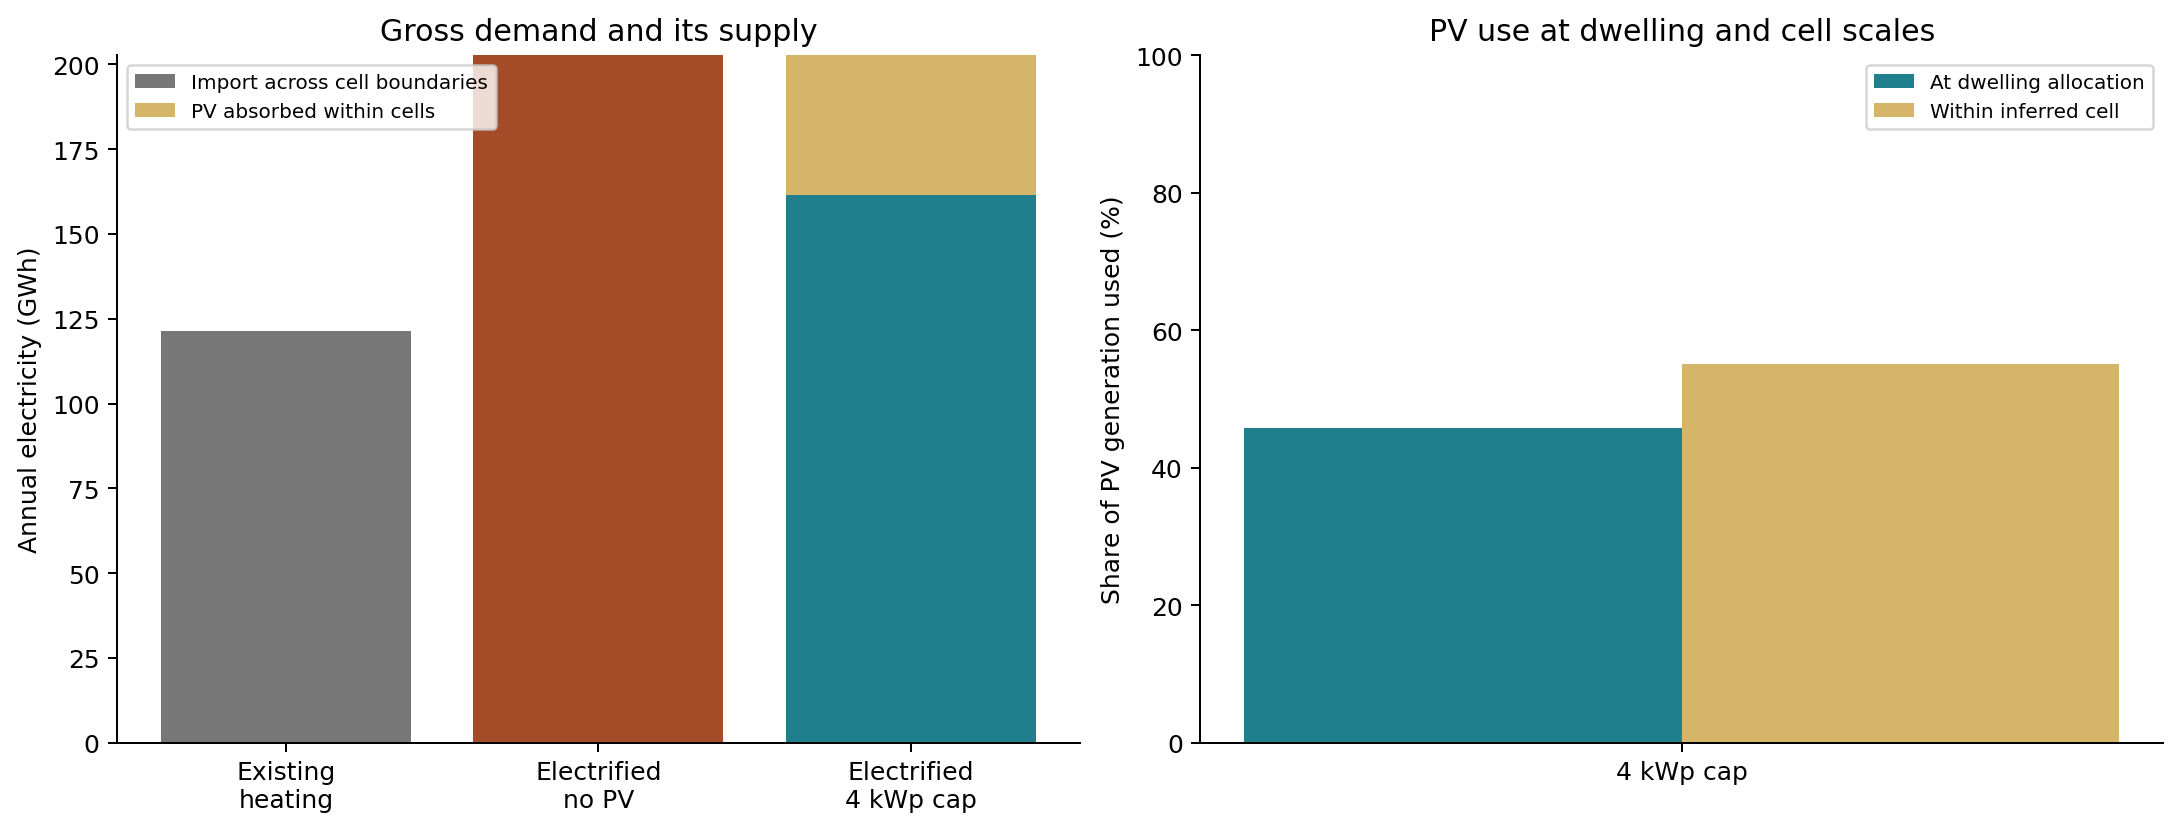

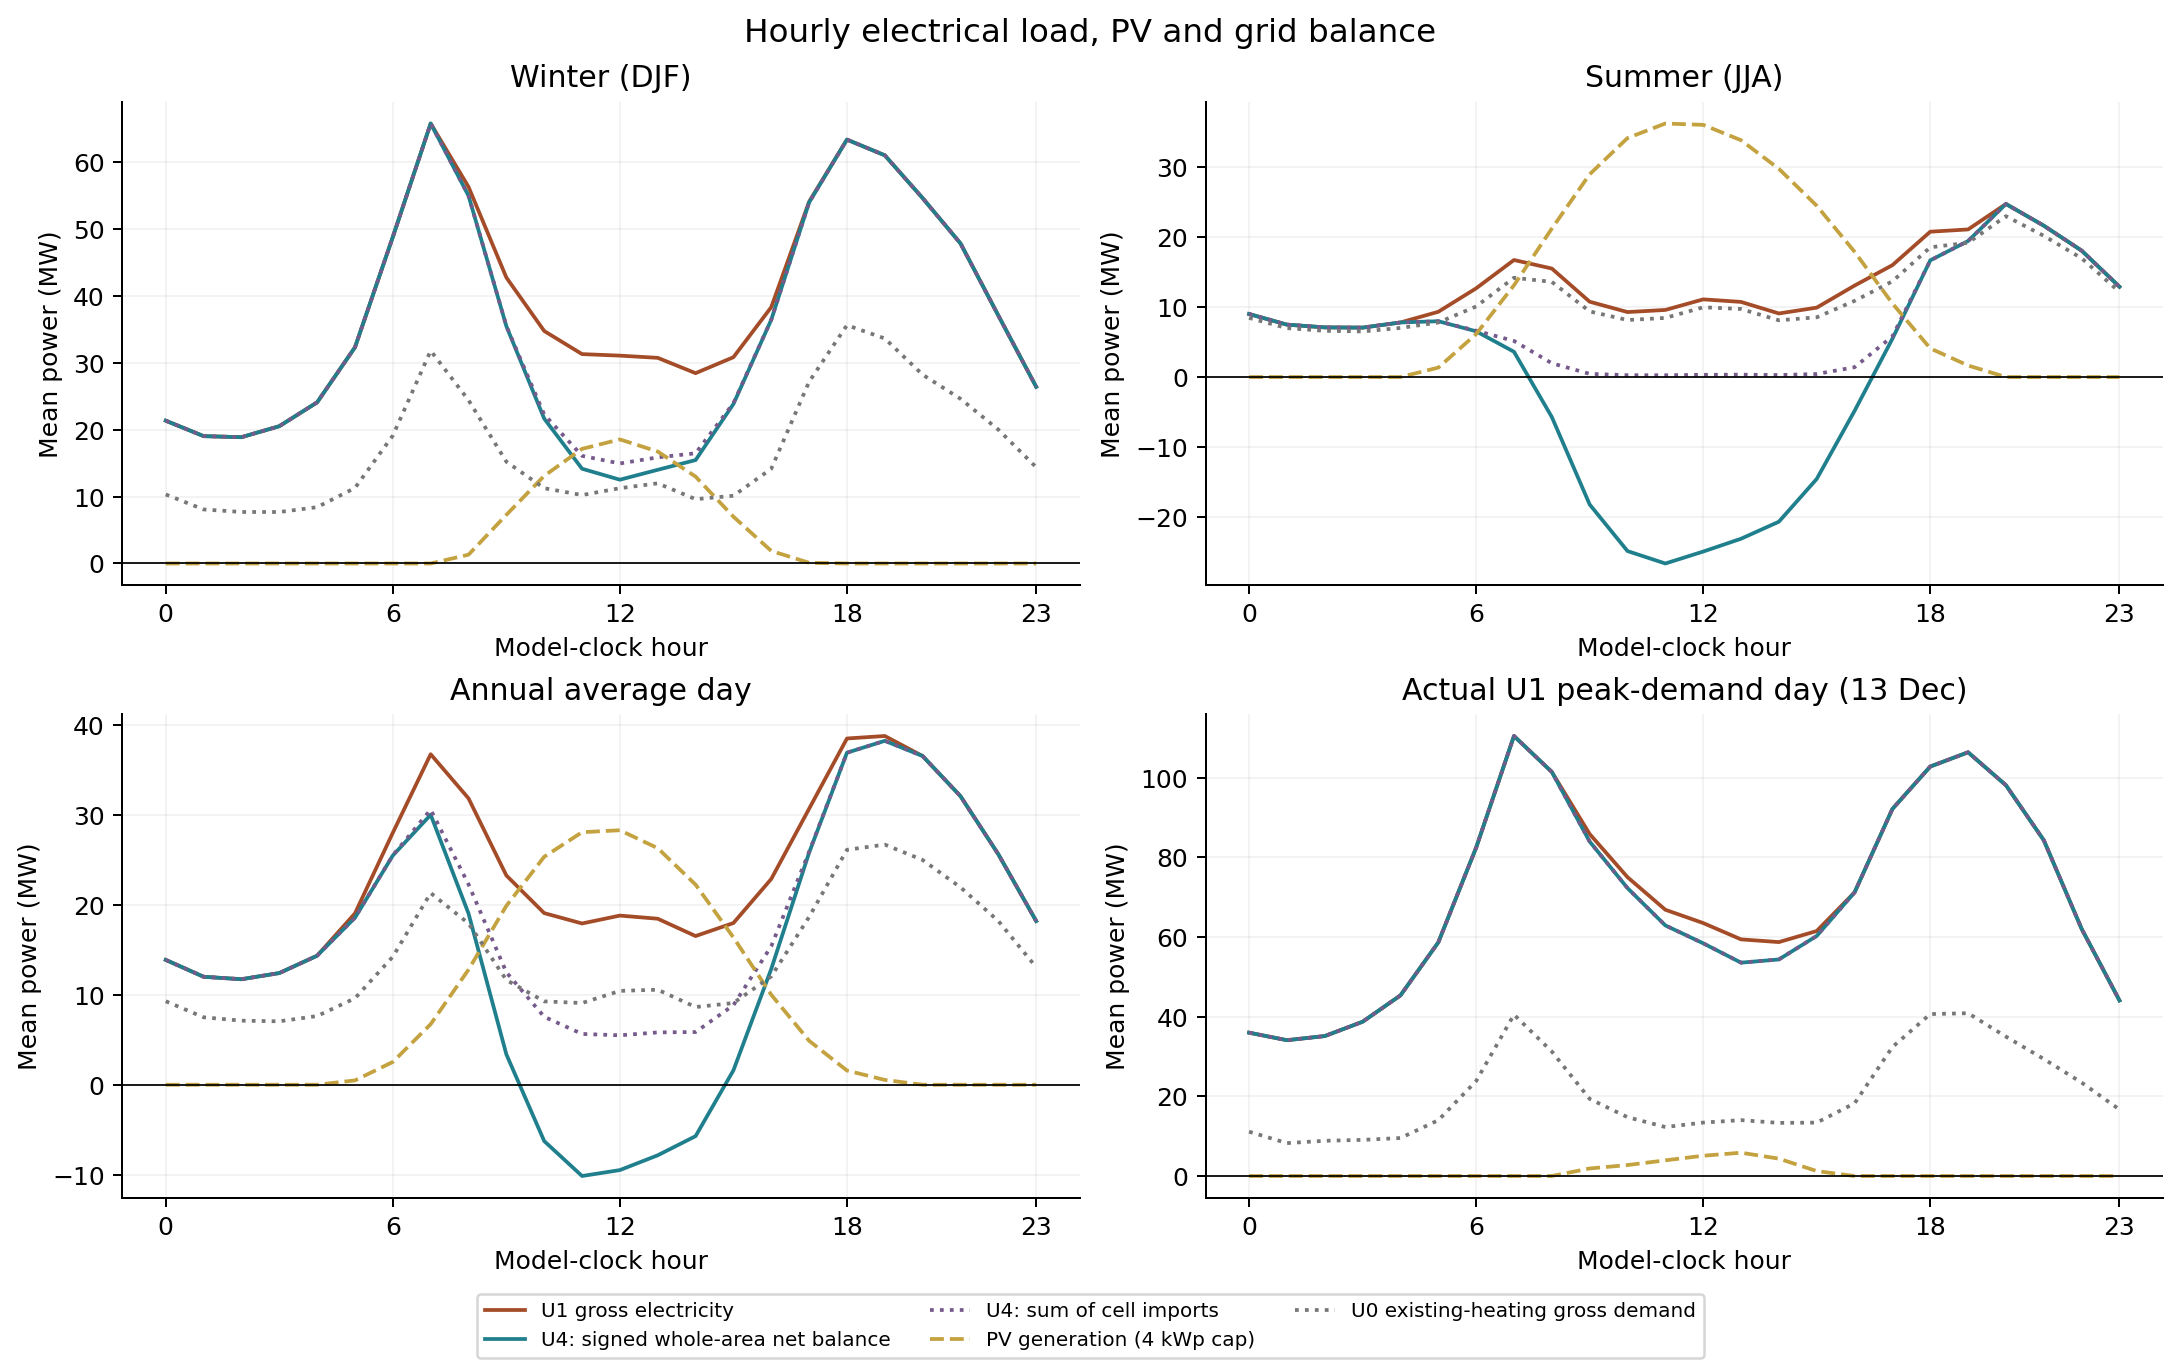

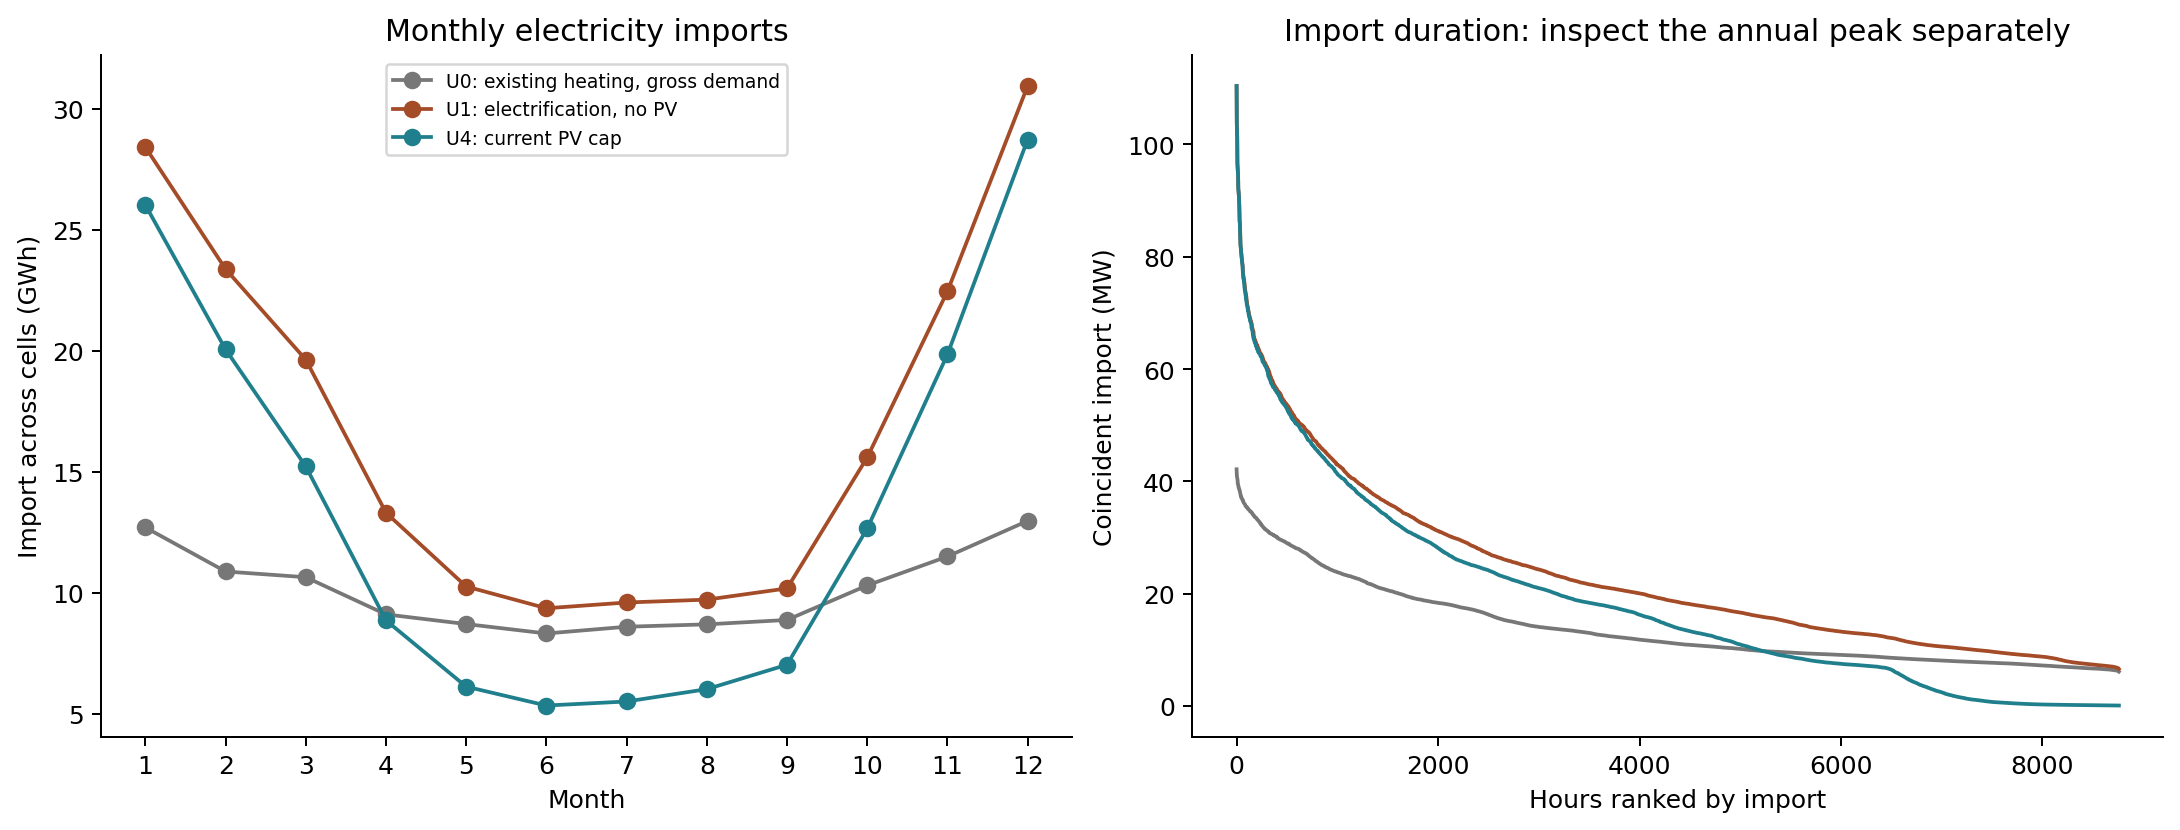

In [8]:
display(Image(filename=str(study['out']/'figures/01_annual_balance.png')))
display(Image(filename=str(study['out']/'figures/02_daily_profiles.png')))
display(Image(filename=str(study['out']/'figures/03_monthly_and_duration.png')))

## 8. Capacity screening and exports

All cases use the same reported ratings. A ratio above 1 is a screening flag, not a verified overload. A ratio below 1 does not establish spare capacity because other loads and network constraints are missing. Export against a nameplate rating is not an approved export limit.

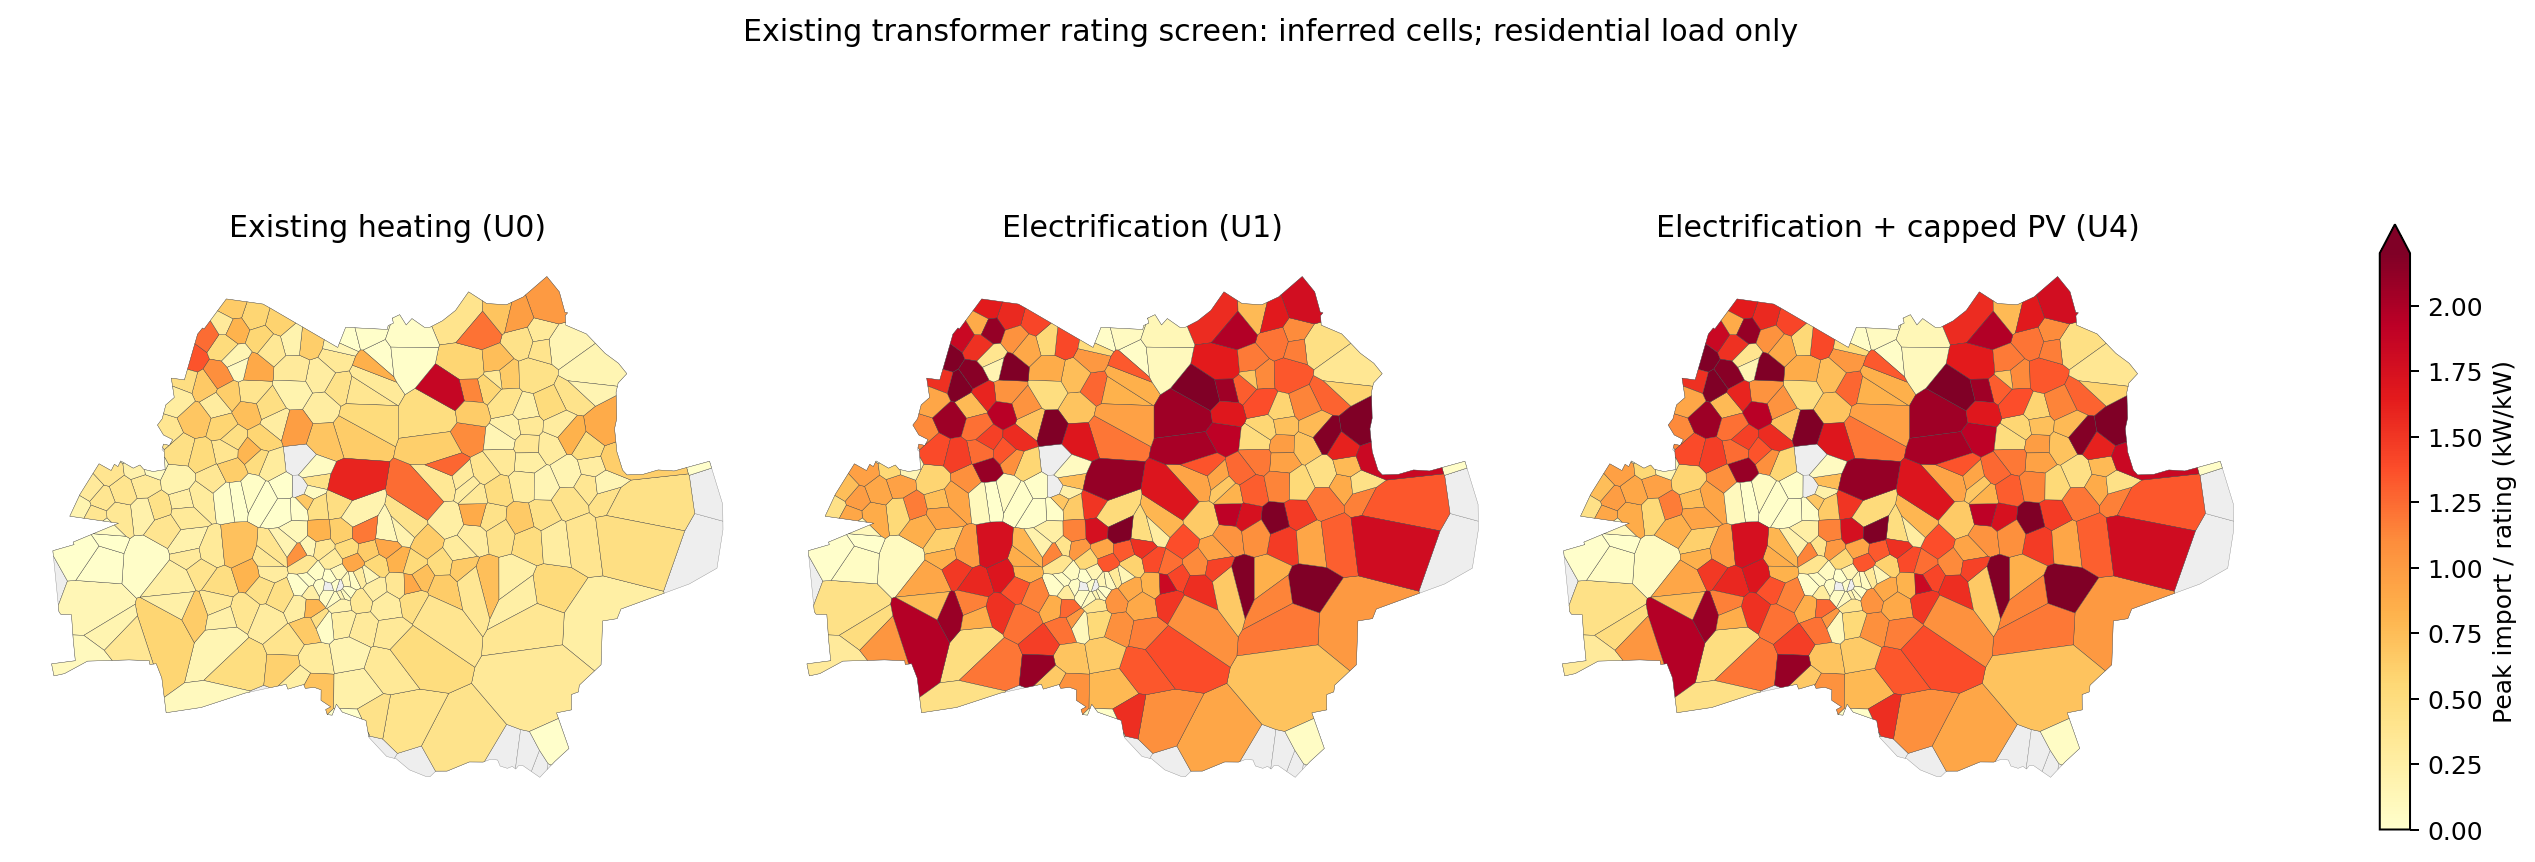

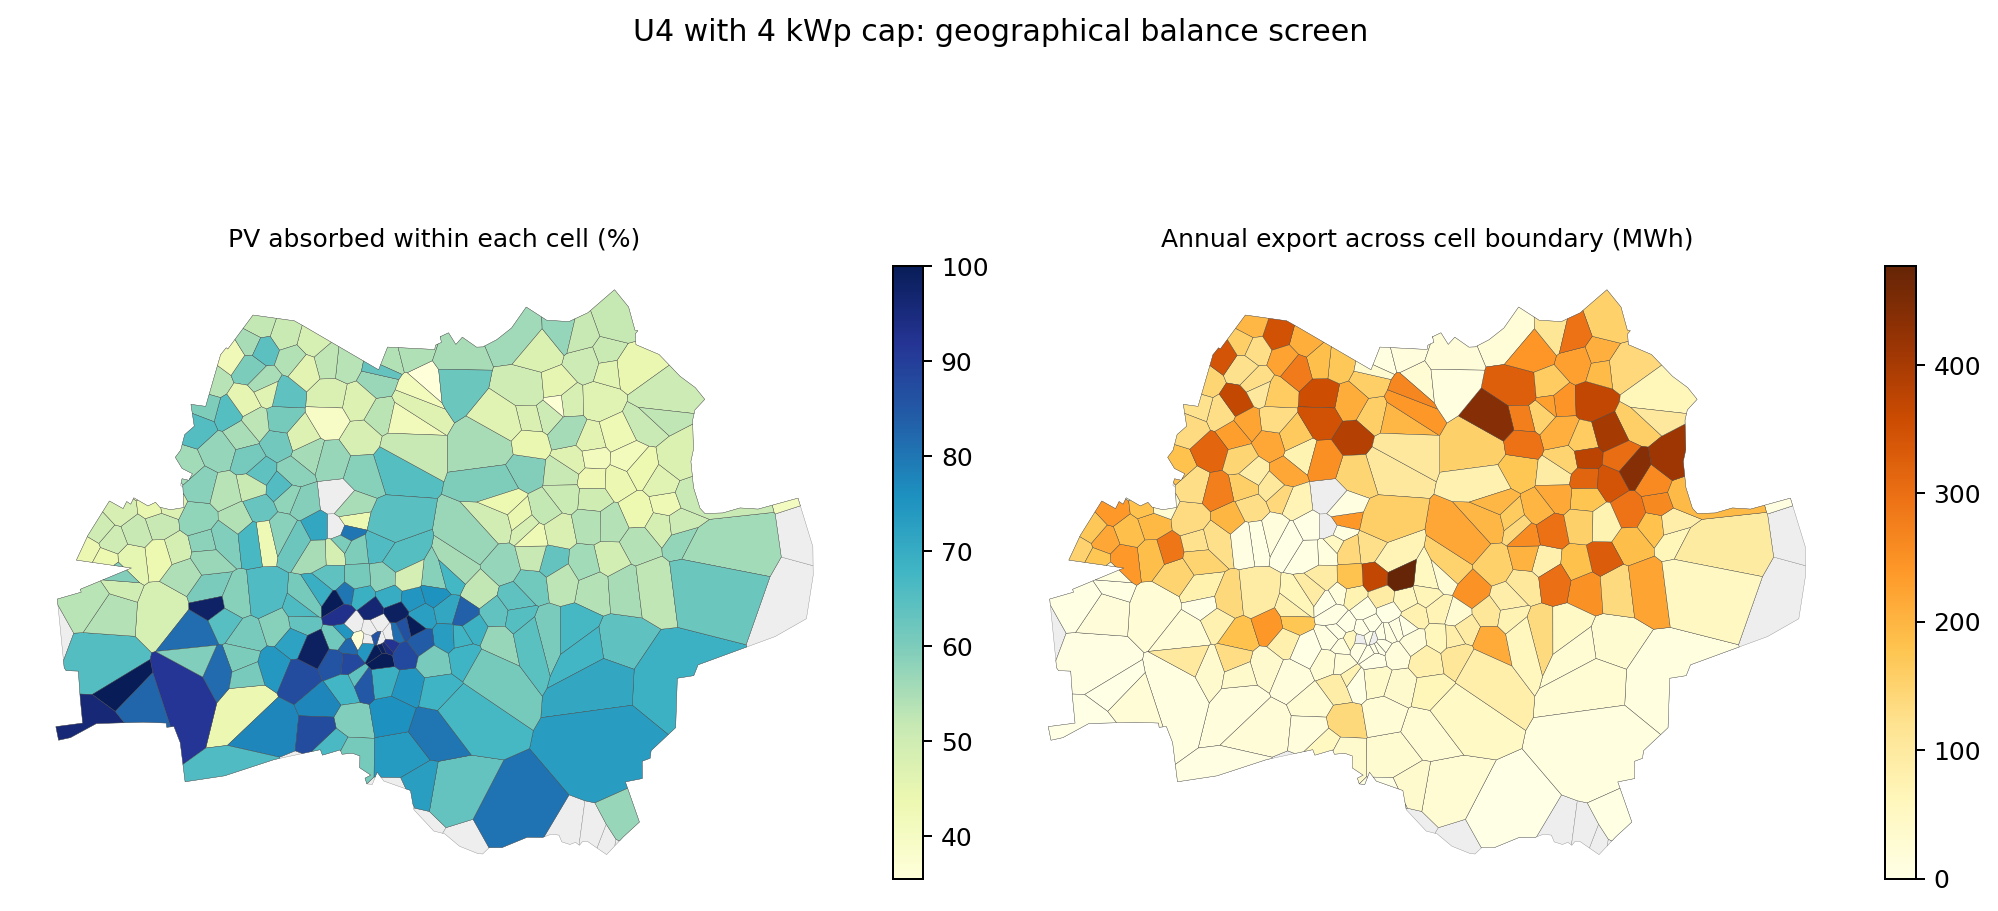

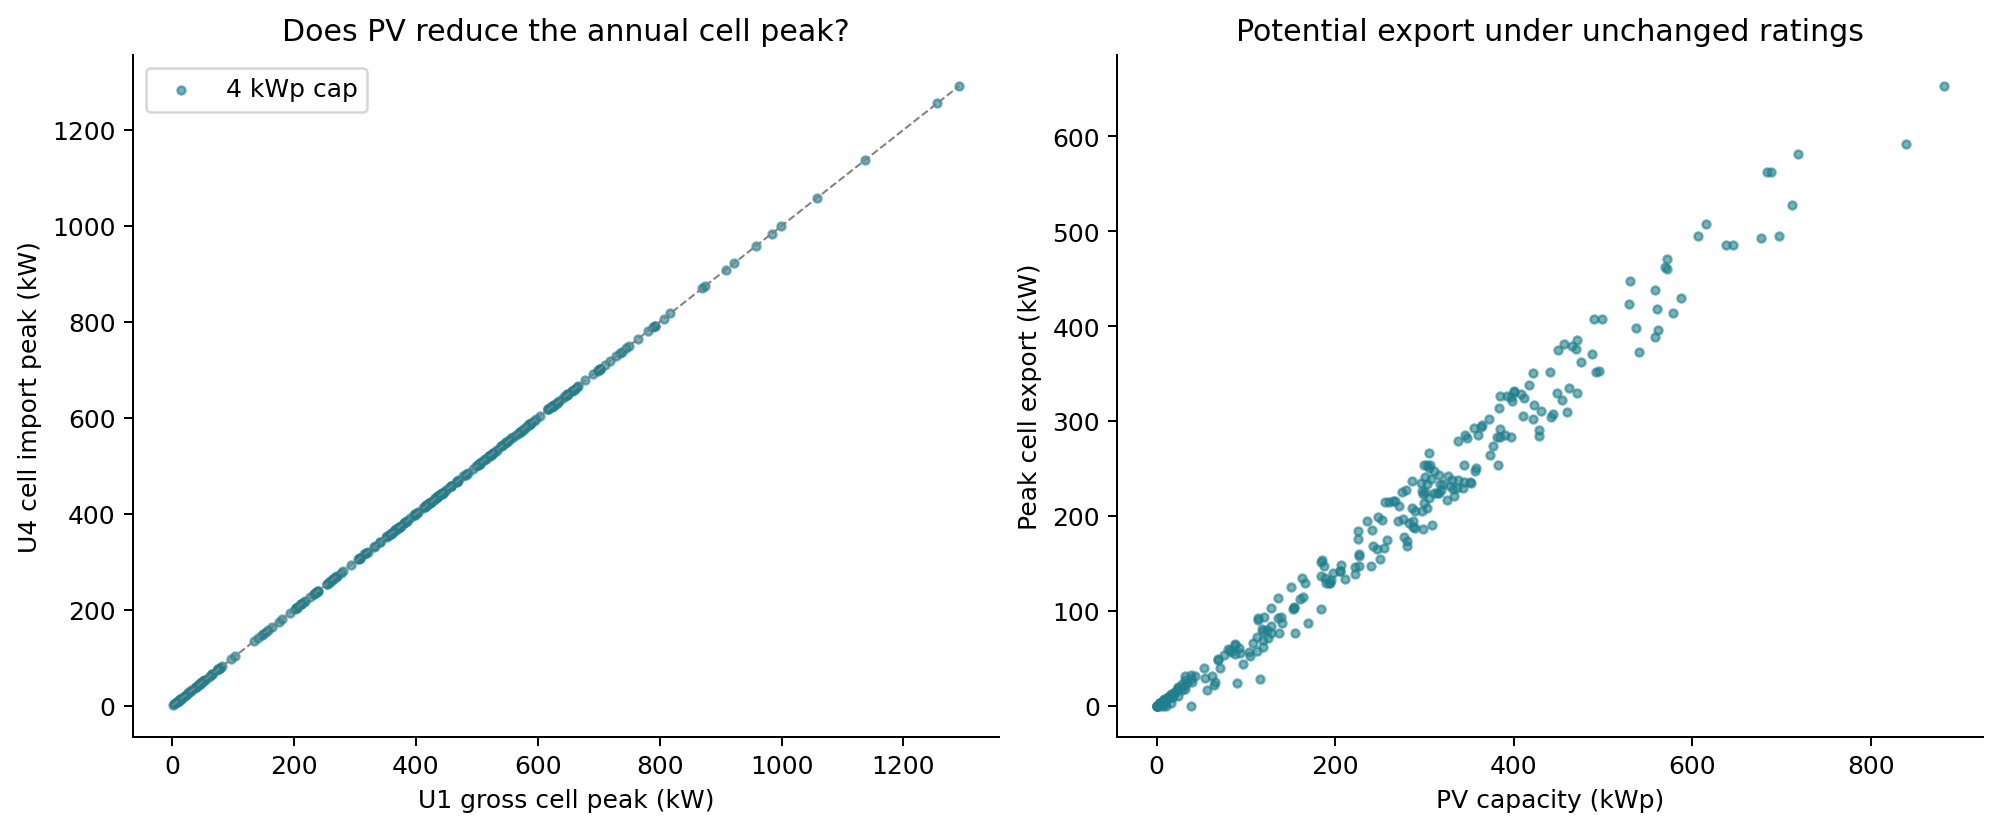

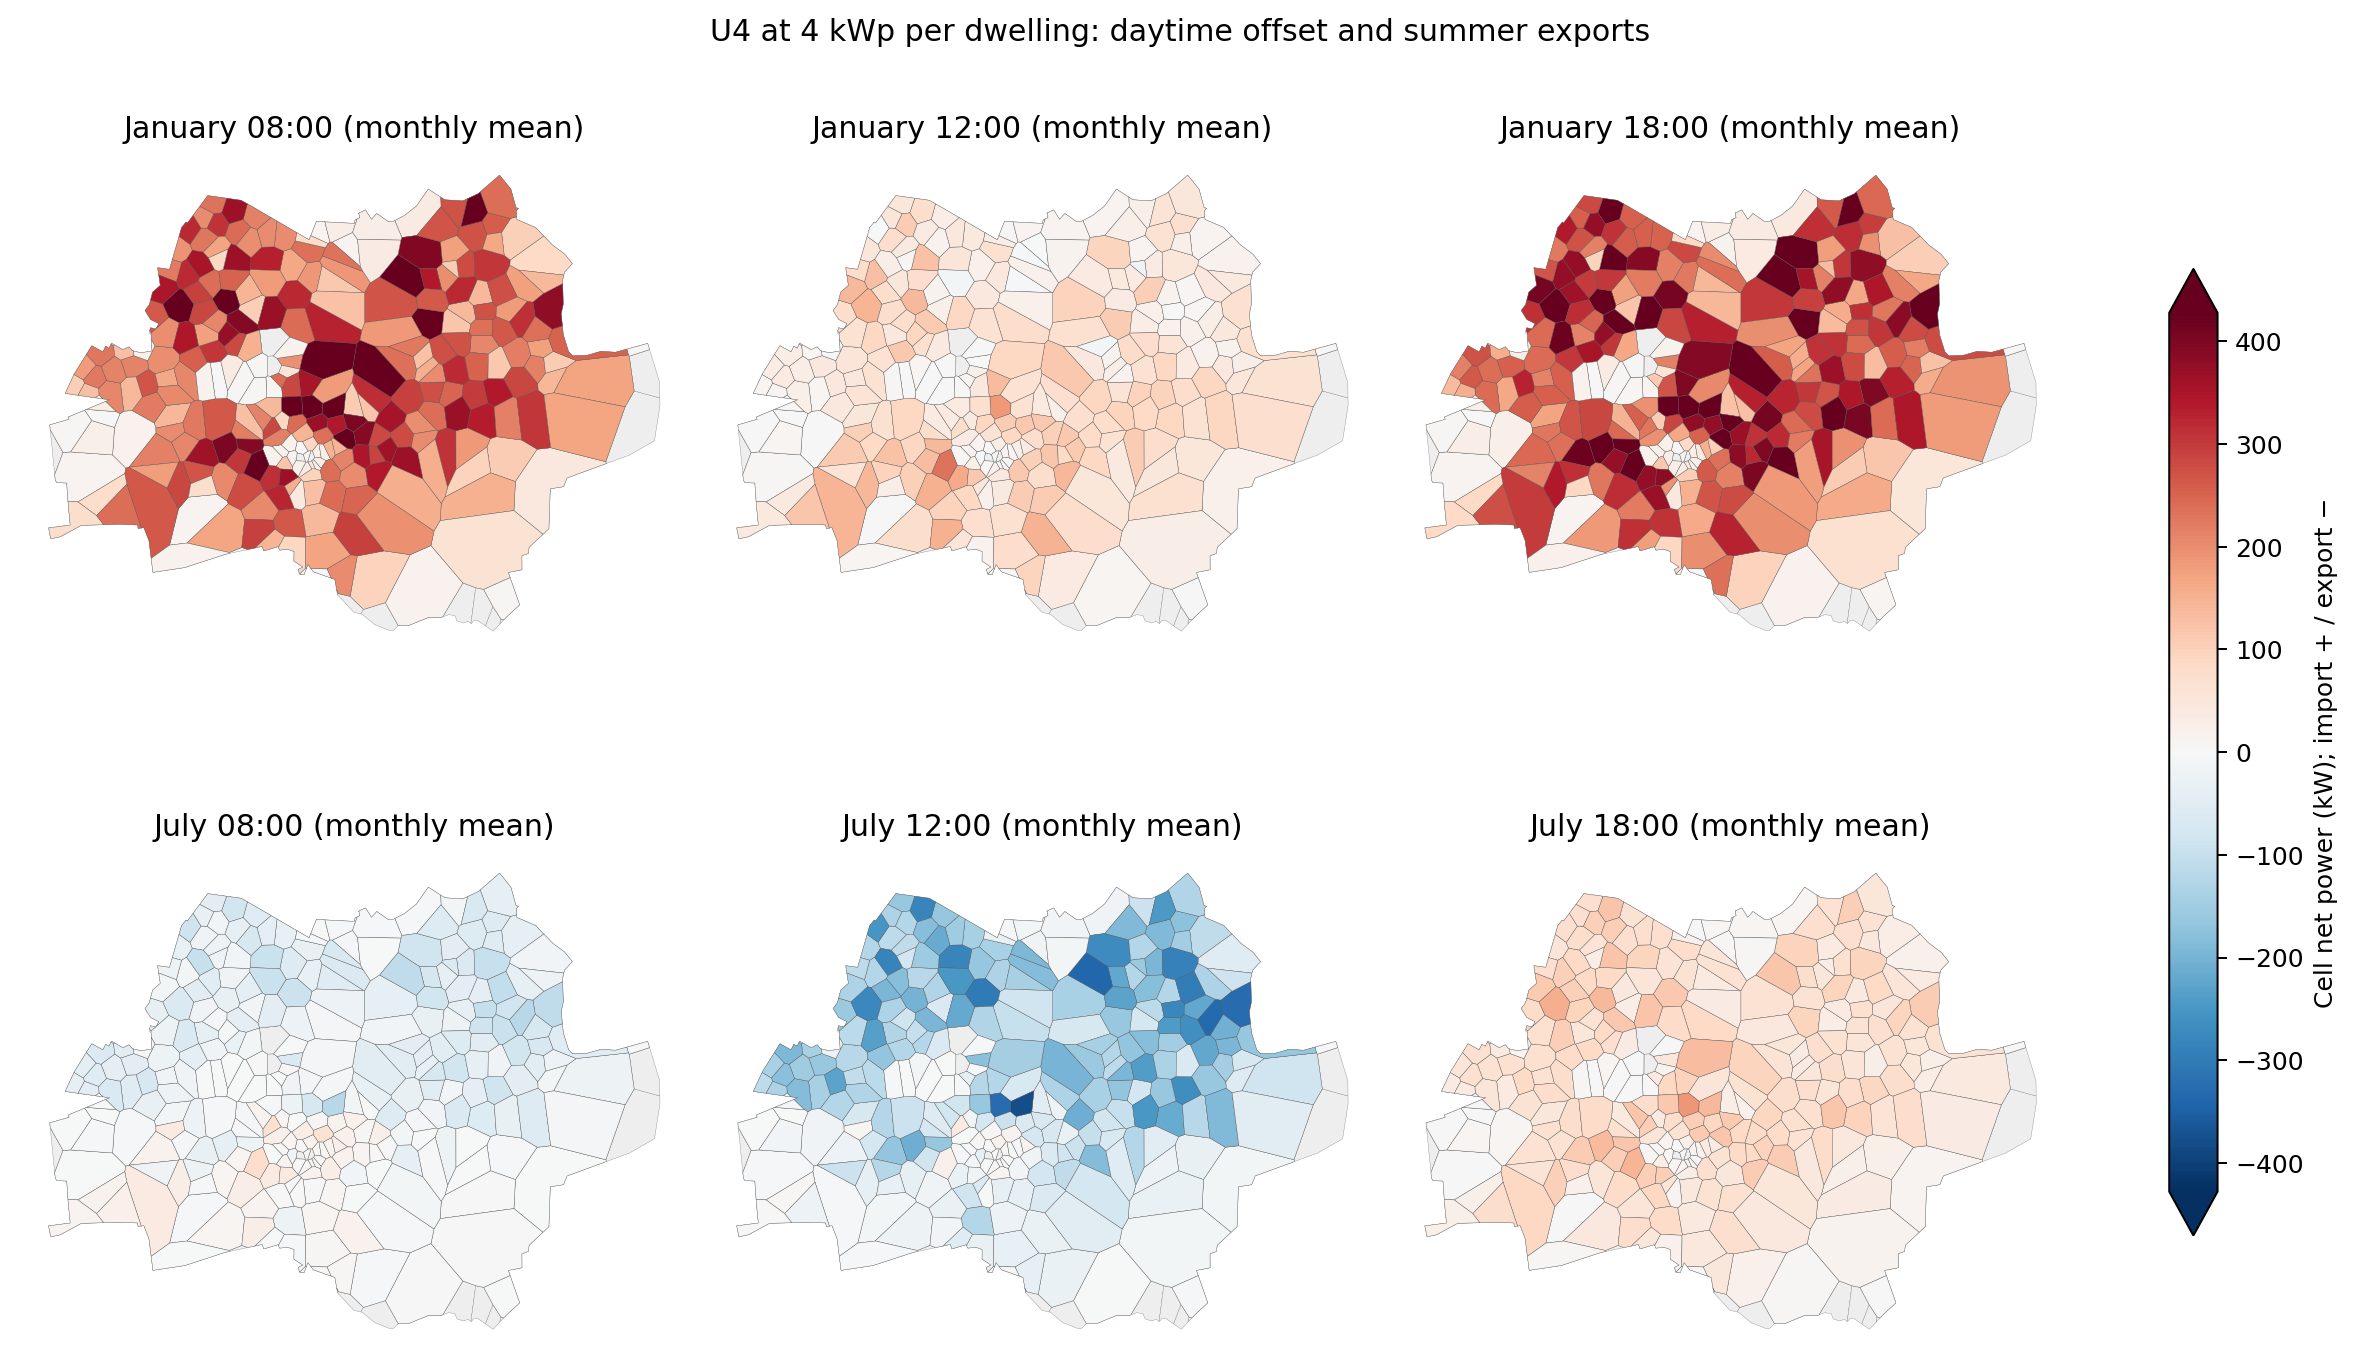

,zone_id,dwelling_count,reported_rating_kVA,gross_peak_kW,cell_import_peak_kW,cell_export_peak_kW,peak_import_rating_ratio,multiple_transformers
548,SUB:SPN-R000000852116-000-001Z,99,100,384.639,384.639,218.666,4.049,False
768,SUB:SPN-S000000174792,239,315,958.315,958.315,581.895,3.202,False
758,SUB:SPN-S000000174640,199,315,788.413,788.413,562.081,2.635,False
625,SUB:SPN-S000000171741,268,315,764.483,764.483,395.524,2.555,False
543,SUB:SPN-R000000843508-000-011Z,23,100,233.093,233.093,59.888,2.454,False
630,SUB:SPN-S000000171746,207,315,701.938,701.938,290.566,2.346,False
696,SUB:SPN-S000000171865,119,300,648.534,648.534,285.481,2.276,False
754,SUB:SPN-S000000174239,311,500,1058.659,1058.659,653.138,2.229,False
634,SUB:SPN-S000000171775,160,315,658.611,658.611,235.649,2.201,False
656,SUB:SPN-S000000171815,122,300,624.359,624.359,231.761,2.191,False


In [9]:
display(Image(filename=str(study['out']/'figures/04_existing_capacity_screen.png')))
display(Image(filename=str(study['out']/'figures/05_local_absorption_and_export.png')))
display(Image(filename=str(study['out']/'figures/06_peaks_and_exports.png')))
display(Image(filename=str(study['out']/'figures/07_time_of_day_cell_balance.png')))
cell_results = study['cell_summary']
display(cell_results.loc[cell_results['case'].eq('U4_capped_south')].nlargest(12,'peak_import_rating_ratio')[
    ['zone_id','dwelling_count','reported_rating_kVA','gross_peak_kW','cell_import_peak_kW',
     'cell_export_peak_kW','peak_import_rating_ratio','multiple_transformers']].round(3))

## 9. Findings calculated from this run

U1 versus U4 isolates the PV effect with unchanged gross electricity demand and population.

In [10]:
u0 = summary.loc['U0_existing_no_pv']
u1 = summary.loc['U1_electrification_no_pv']
u4 = summary.loc['U4_capped_south']
peak_change = u1.coincident_cell_import_peak_MW-u4.coincident_cell_import_peak_MW
peak_pct = 100*peak_change/u1.coincident_cell_import_peak_MW
text = f"""The included residential population has **{u0.gross_demand_GWh:.2f} GWh/year** of gross electricity demand with existing heating, increasing to **{u1.gross_demand_GWh:.2f} GWh/year** in U1. The 4 kWp cap gives **{u4.capacity_MWp:.2f} MWp** and **{u4.PV_GWh:.2f} GWh/year** of generation.

Dwelling self-consumption is **{u4.dwelling_self_consumption_pct:.1f}%** of PV generation. At the inferred cell boundary, **{u4.cell_PV_absorption_pct:.1f}%** coincides with demand. Cell imports are **{u4.cell_import_GWh:.2f} GWh/year**, and exports **{u4.cell_export_GWh:.2f} GWh/year**.

The maximum of the simultaneous sum of cell imports changes from **{u1.coincident_cell_import_peak_MW:.2f} MW** to **{u4.coincident_cell_import_peak_MW:.2f} MW**, a reduction of **{peak_change:.3f} MW ({peak_pct:.2f}%)**. This is not the sum of individual cell maxima."""
display(Markdown(text))
(study['out']/'findings.md').write_text(text,encoding='utf-8')
if settings.orientation_sensitivity:
    display(summary.loc[['U4_capped_south','U4_capped_east_west'],columns].round(3))

<IPython.core.display.Markdown object>

,capacity_MWp,gross_demand_GWh,PV_GWh,meter_import_GWh,meter_export_GWh,cell_import_GWh,cell_export_GWh,dwelling_self_consumption_pct,cell_PV_absorption_pct,coincident_cell_import_peak_MW
case,,,,,,,,,,
U4_capped_south,69.363,202.778,75.247,168.386,40.855,161.367,33.835,45.705,55.034,110.419
U4_capped_east_west,69.363,202.778,75.247,167.378,39.847,160.400,32.868,47.045,56.319,110.419


## 10. Verification and reproducibility

Each dwelling's annual electricity is reconciled to stored U0/U1 results. Every aggregated hour is checked against canonical accounting. Capped PV reproduces original U4 capacity and annual yield. Source-roof allocations, night-time output, and load/generation/import/export identities are checked. A two-dwelling example tests the distinction between household and cell export.

These results do not establish verified network connections, voltage/security compliance, financial benefits from community sharing, or dynamic microgrid reconfiguration.

In [11]:
report = B.write_report(study)
check_table = pd.DataFrame.from_dict(study['checks'],orient='index')
display(check_table.fillna(''))
print('All numerical checks passed:',all(v['passed'] for k,v in study['checks'].items()
                                       if k!='mapped_points_in_illustrative_cells'))
print('Manifest:',study['out']/'manifest.json')
print('Report:',report)
print('Summary:',study['out']/'scenario_summary.csv')

,passed,max_abs_error,inside,total,note
rating_sources_agree,True,0.0,,,
no_duplicated_roof_potential,True,,,,
U1_U4_same_gross_demand,True,0.0,,,
current_U4_capacity_reproduced,True,0.0,,,
current_U4_annual_PV_reproduced,True,0.0,,,
PV_shapes_sum_to_one,True,0.0,,,
PV_and_demand_weather_temperatures_align,True,0.0,,,
synthetic_meter_vs_cell_balance,True,0.0,,,
synthetic_no_PV_and_no_load_import,True,0.0,,,
synthetic_no_PV_and_no_load_export,True,0.0,,,


All numerical checks passed: True
Manifest: LOCAL_PATH/manifest.json
Report: LOCAL_PATH/README.md
Summary: LOCAL_PATH/scenario_summary.csv


## 11. Refreshed U0–U5 comparison and incentive accounts

This section refreshes the full six-scenario infrastructure comparison from the current saved scenario files. The incentive revision is applied after energy simulation: it changes grants, net investment, payback and cost-based rankings. Under these fixed intervention packages, it does not change physical adoption, electricity demand, rooftop generation or transformer ratings. No grant-driven uptake model is assumed.

The accompanying financial table uses all 28,663 planning-ward dwellings; the hourly network screen consistently excludes the one unassigned dwelling. Financial PV accounting retains the configured annual self-consumption share, whereas the network analysis calculates hourly coincidence.

          capacity_MWp  gross_demand_GWh     PV_GWh  meter_import_GWh  meter_export_GWh  cell_import_GWh  cell_export_GWh  dwelling_self_consumption_pct  cell_PV_absorption_pct  additional_cell_coincidence_GWh  coincident_cell_import_peak_MW  coincident_cell_export_peak_MW  cells_above_import_rating_screen  cells_above_export_rating_screen  median_peak_import_rating_pct            peak_hour
scenario                                                                                                                                                                                                                                                                                                                                                                                                 
U0            0.000000        121.277116   0.000000        121.277116          0.000000       121.277116         0.000000                            NaN                     NaN                         0.000000   

All checks passed: True


,scenario,cell_import_GWh,cell_export_GWh,coincident_cell_import_peak_MW,cells_above_import_rating_screen,cells_above_export_rating_screen
0,U0,121.277,0.000,42.132,12.0,0.0
1,U1,202.778,0.000,110.419,130.0,0.0
2,U2,118.195,0.000,40.822,12.0,0.0
3,U3,180.948,0.000,92.446,99.0,0.0
4,U4,161.367,33.835,110.419,130.0,19.0
5,U5,140.981,35.280,92.446,99.0,19.0


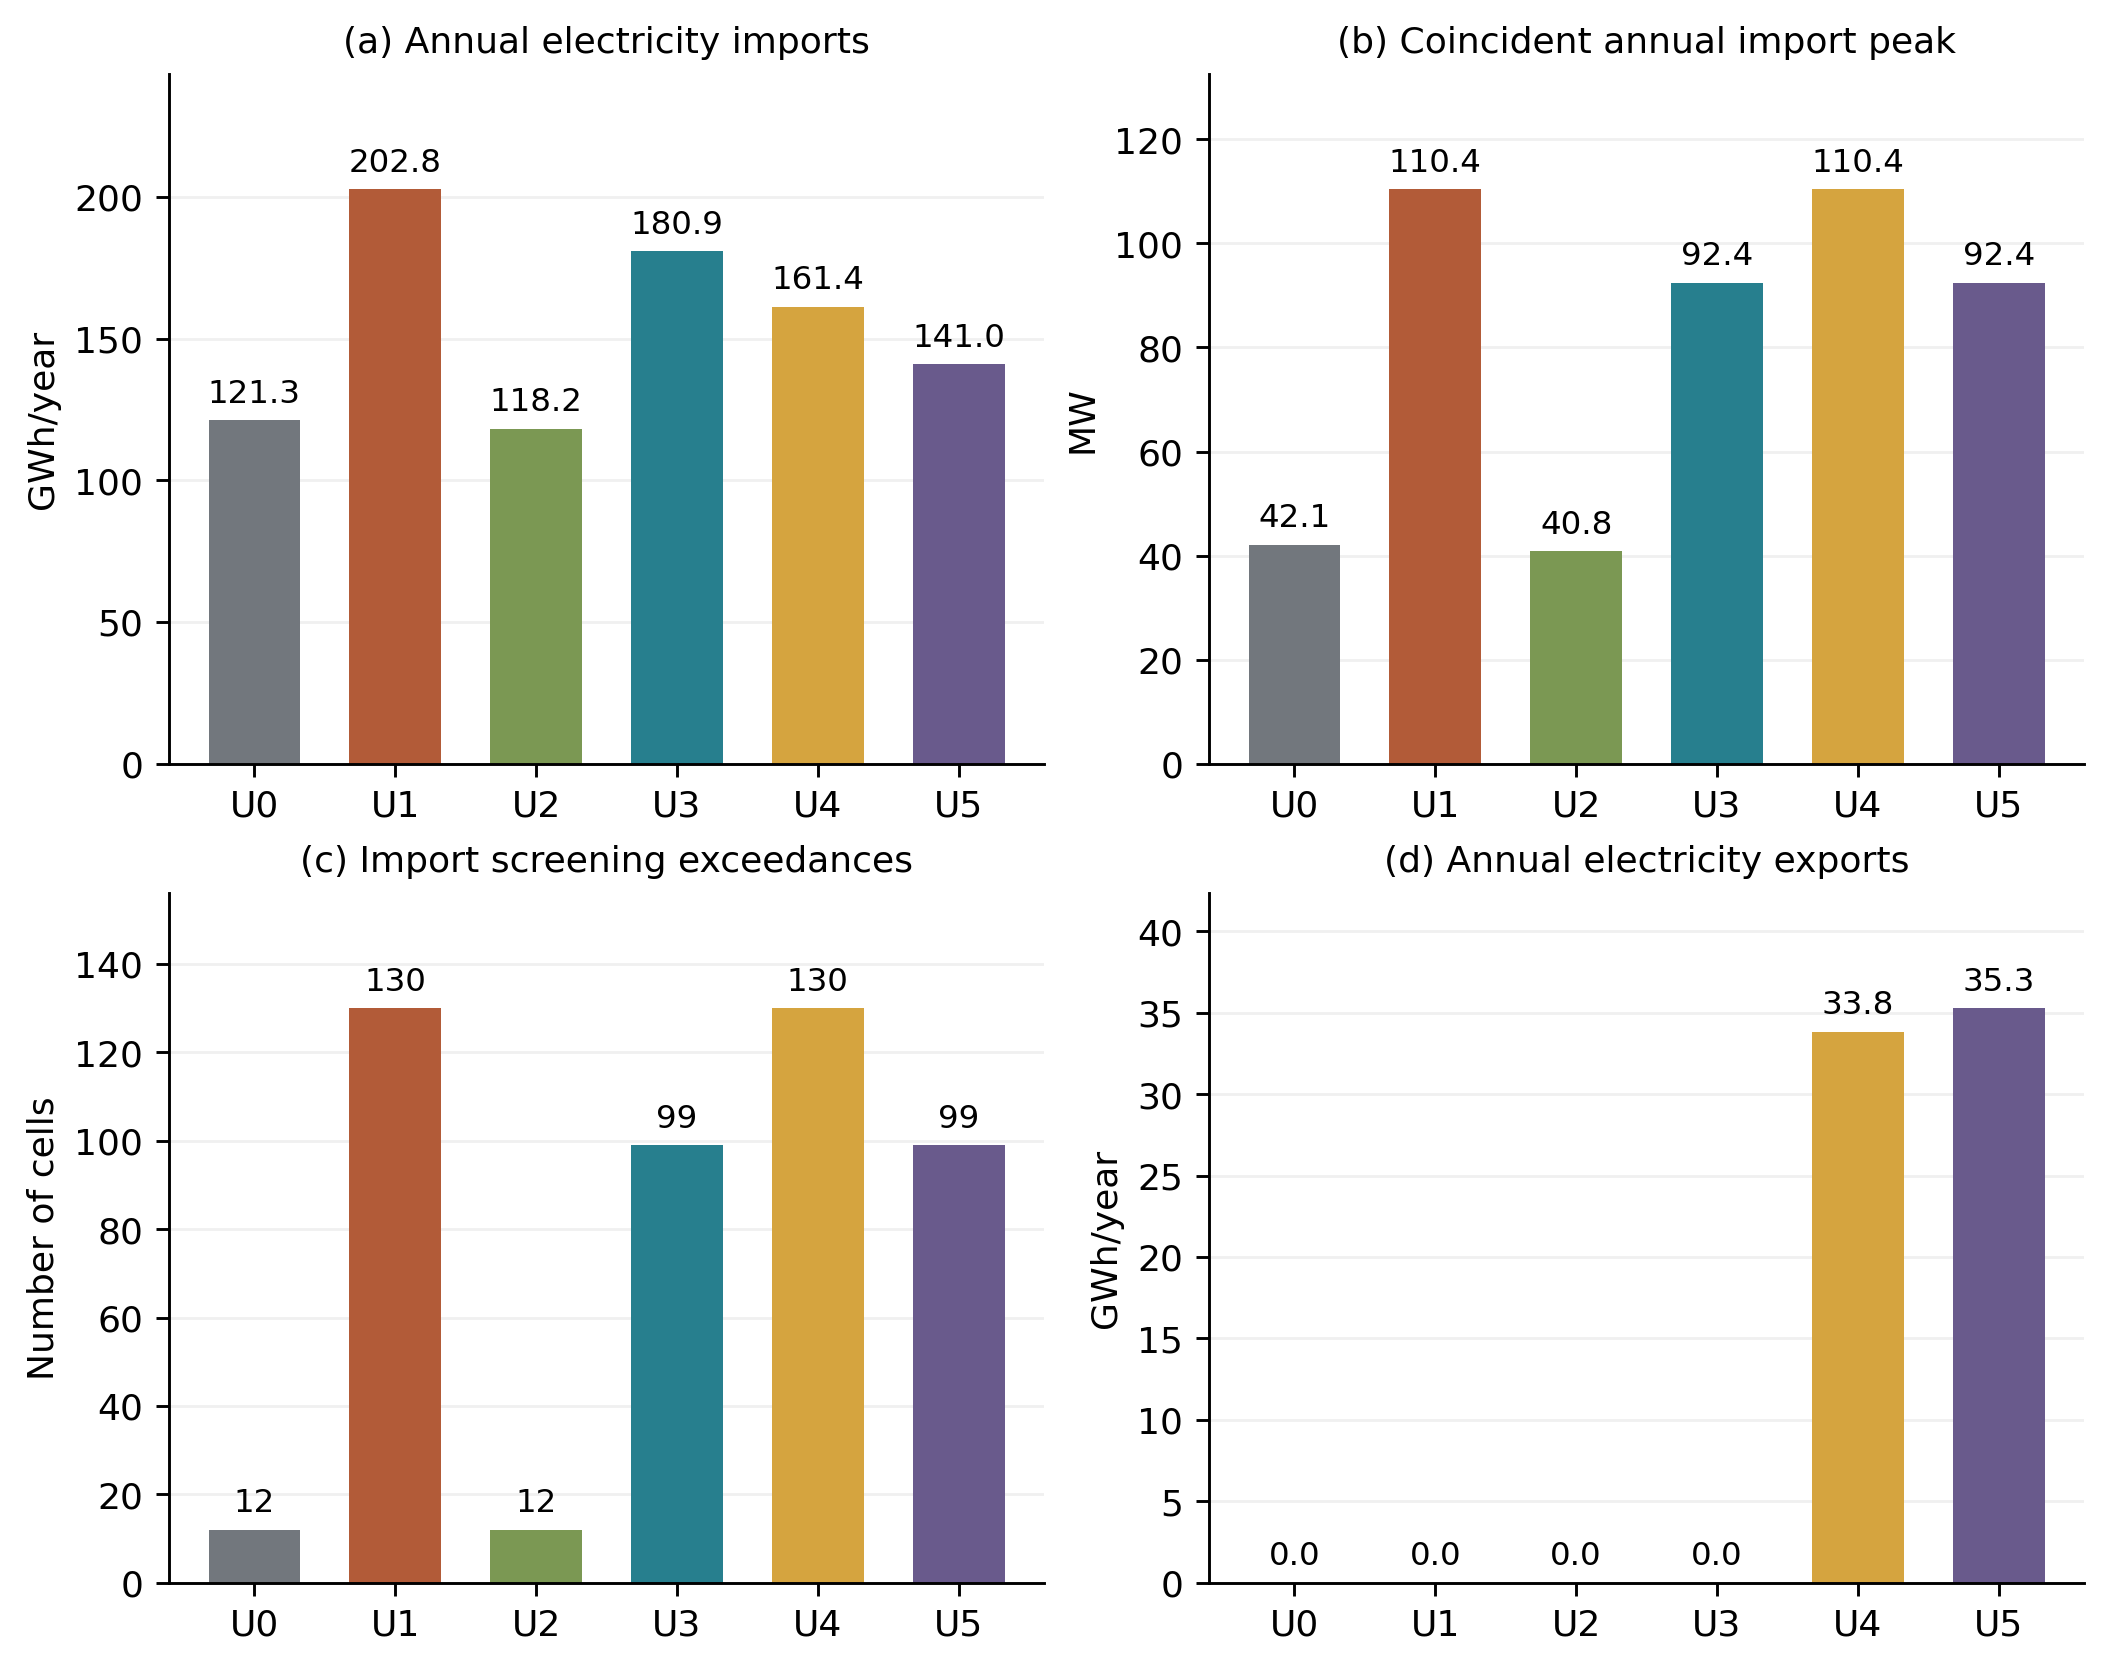

,capex_gross_MGBP,incentives_MGBP,net_capex_MGBP
scenario,,,
U0_baseline,0.000,0.000,0.000
U1_electrification,266.238,160.768,105.470
U2_envelope,92.085,13.834,78.250
U3_envelope_elec,329.963,173.668,156.295
U4_elec_pv,388.327,160.768,227.560
U5_envelope_elec_pv,452.053,173.668,278.384


Active incentive parameter file: parameters/finance_incentives/incentives_2026.json


In [12]:
import runpy
runpy.run_path(str(ROOT/'analysis/chapter4_infrastructure.py'), run_name='__main__')
all_cases=pd.read_csv(ROOT/'outputs/current/chapter4_infrastructure/all_scenario_summary.csv')
display(all_cases[['scenario','cell_import_GWh','cell_export_GWh',
                   'coincident_cell_import_peak_MW','cells_above_import_rating_screen',
                   'cells_above_export_rating_screen']].round(3))
display(Image(filename=str(ROOT/'outputs/current/chapter4_infrastructure/figures/scenario_infrastructure.png')))
ward_finance=pd.read_csv(ROOT/'outputs/current/scenarios/planning_ward_summary.csv')
finance=ward_finance.groupby('scenario')[['capex_gross_MGBP','incentives_MGBP']].sum()
finance['net_capex_MGBP']=finance.capex_gross_MGBP-finance.incentives_MGBP
finance.to_csv(study['out']/'current_incentive_investment_summary.csv')
display(finance.round(3))
print('Active incentive parameter file: parameters/finance_incentives/incentives_2026.json')

## References

- Park, J. and Wang, T.-H. (2024). *An Integrated Urban Building Energy Benchmarking Workflow to Support Urban Energy Evaluation: A Case Study of Sheffield UK*. Buildings, 14, 3398. https://doi.org/10.3390/buildings14113398
- Energy Saving Trust. *Solar panels: costs, savings and benefits explained*. https://energysavingtrust.org.uk/advice/solar-panels/?loc=england (accessed 8 October 2026).
- pvlib: [EPW and timestamp convention](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.iotools.read_epw.html); [plane-of-array irradiance](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.irradiance.get_total_irradiance.html).
- EnerMap current results and parameters: exact input/source hashes are recorded in outputs/current/u4_pv_balance/manifest.json. Research PDF supplied by the user: LOCAL_PATH/really_relevent_study.pdf.
